# DX 704 Week 9 Project

This week's project will build an email spam classifier based on the Enron email data set.
You will perform your own feature extraction, and use naive Bayes to estimate the probability that a particular email is spam or not.
Finally, you will review the tradeoffs from different thresholds for automatically sending emails to the junk folder.

The full project description and a template notebook are available on GitHub: [Project 9 Materials](https://github.com/bu-cds-dx704/dx704-project-09).


## Example Code

You may find it helpful to refer to these GitHub repositories of Jupyter notebooks for example code.

* https://github.com/bu-cds-omds/dx601-examples
* https://github.com/bu-cds-omds/dx602-examples
* https://github.com/bu-cds-omds/dx603-examples
* https://github.com/bu-cds-omds/dx704-examples

Any calculations demonstrated in code examples or videos may be found in these notebooks, and you are allowed to copy this example code in your homework answers.

## Part 1: Download Data Set

We will be using the Enron spam data set as prepared in this GitHub repository.

https://github.com/MWiechmann/enron_spam_data

You may need to download this differently depending on your environment.

In [1]:
!wget https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip

--2026-11-02 23:40:31--  https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip [following]
--2026-11-02 23:40:31--  https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15642124 (15M) [application/zip]
Saving to: ‘enron_spam_data.zip’

enron_spam_data.zip 100%[===================>]  14.92M  70.9MB/s    in 0.2s    

2026-11-02 23:40:32 (70.9 MB/s) - ‘enron_spa

In [4]:
import pandas as pd

In [5]:
# pandas can read the zip file directly
enron_spam_data = pd.read_csv("enron_spam_data.zip")
enron_spam_data

,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14
...,...,...,...,...,...
33711,33711,= ? iso - 8859 - 1 ? q ? good _ news _ c = eda...,"hello , welcome to gigapharm onlinne shop .\np...",spam,2005-07-29
33712,33712,all prescript medicines are on special . to be...,i got it earlier than expected and it was wrap...,spam,2005-07-29
33713,33713,the next generation online pharmacy .,are you ready to rock on ? let the man in you ...,spam,2005-07-30
33714,33714,bloow in 5 - 10 times the time,learn how to last 5 - 10 times longer in\nbed ...,spam,2005-07-30


In [6]:
(enron_spam_data["Spam/Ham"] == "spam").mean()

np.float64(0.5092834262664611)

## Part 2: Design a Feature Extractor

Design a feature extractor for this data set and write out two files of features based on the text.
Don't forget that both the Subject and Message columns are relevant sources of text data.
For each email, you should count the number of repetitions of each feature present.
The auto-grader will assume that you are using a multinomial distribution in the following problems.

In [12]:
# YOUR CHANGES HERE

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from scipy.sparse import save_npz

df = enron_spam_data.copy()

df["Subject"] = df["Subject"].fillna("")
df["Message"] = df["Message"].fillna("")

df["Text"] = df["Subject"] + " " + df["Message"]

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Spam/Ham"]
)


vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    min_df=2
)

# Learn vocabulary using training data only
X_train = vectorizer.fit_transform(train_df["Text"])

# Apply same vocabulary to testing data
X_test = vectorizer.transform(test_df["Text"])


save_npz("train-features.npz", X_train)
save_npz("test-features.npz", X_test)

# Save labels separately
train_df[["Spam/Ham"]].to_csv(
    "train-labels.tsv",
    sep="\t",
    index=False
)

test_df[["Spam/Ham"]].to_csv(
    "test-labels.tsv",
    sep="\t",
    index=False
)

print("FEATURE EXTRACTION COMPLETE")
print("-" * 40)

print("Training emails:", X_train.shape[0])
print("Testing emails:", X_test.shape[0])
print("Unique features:", X_train.shape[1])

print("\nTraining feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

print("\nFiles saved successfully.")


FEATURE EXTRACTION COMPLETE
----------------------------------------
Training emails: 26972
Testing emails: 6744
Unique features: 74131

Training feature matrix: (26972, 74131)
Testing feature matrix: (6744, 74131)

Files saved successfully.


Assign a row to the test data set if `Message ID % 30 == 0` and assign it to the training data set otherwise.
Write two files, "train-features.tsv" and "test-features.tsv" with two columns, Message ID and features_json.
The features_json column should contain a JSON dictionary where the keys are your feature names and the values are integer feature values.
This will give us a sparse feature representation.


In [13]:
# YOUR CHANGES HERE


import pandas as pd
import json
from sklearn.feature_extraction.text import CountVectorizer

df = enron_spam_data.copy()


df["Subject"] = df["Subject"].fillna("").astype(str)
df["Message"] = df["Message"].fillna("").astype(str)

df["Text"] = df["Subject"] + " " + df["Message"]


train_df = df[df["Message ID"] % 30 != 0].copy()
test_df = df[df["Message ID"] % 30 == 0].copy()

vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b"
)

# Fit vocabulary on training data only
X_train = vectorizer.fit_transform(train_df["Text"])
X_test = vectorizer.transform(test_df["Text"])

feature_names = vectorizer.get_feature_names_out()



def create_feature_file(dataframe, matrix, filename):

    feature_rows = []

    for i, message_id in enumerate(dataframe["Message ID"]):

        row = matrix.getrow(i)

        features = {
            feature_names[index]: int(count)
            for index, count in zip(row.indices, row.data)
        }

        feature_rows.append({
            "Message ID": message_id,
            "features_json": json.dumps(features)
        })

    output_df = pd.DataFrame(feature_rows)

    output_df.to_csv(
        filename,
        sep="\t",
        index=False
    )

    print(f"Saved {filename}: {len(output_df)} emails")



create_feature_file(
    train_df,
    X_train,
    "train-features.tsv"
)

create_feature_file(
    test_df,
    X_test,
    "test-features.tsv"
)


print("\nFEATURE EXTRACTION COMPLETE")
print("-" * 40)

print("Training emails:", len(train_df))
print("Testing emails:", len(test_df))
print("Unique features:", len(feature_names))

print("\nExample feature dictionary:")
print(json.dumps(
    json.loads(
        pd.read_csv(
            "train-features.tsv",
            sep="\t"
        ).iloc[0]["features_json"]
    ),
    indent=2
)[:1000])


Saved train-features.tsv: 32592 emails
Saved test-features.tsv: 1124 emails

FEATURE EXTRACTION COMPLETE
----------------------------------------
Training emails: 32592
Testing emails: 1124
Unique features: 155957

Example feature dictionary:
{
  "vastar": 6,
  "resources": 4,
  "inc": 4,
  "gary": 2,
  "production": 3,
  "from": 3,
  "the": 8,
  "high": 2,
  "island": 2,
  "larger": 2,
  "block": 2,
  "a": 6,
  "1": 4,
  "2": 5,
  "commenced": 1,
  "on": 7,
  "saturday": 1,
  "at": 3,
  "00": 2,
  "p": 1,
  "m": 2,
  "about": 1,
  "6": 2,
  "500": 4,
  "gross": 3,
  "carlos": 3,
  "expects": 2,
  "between": 1,
  "9": 14,
  "and": 4,
  "10": 11,
  "000": 18,
  "for": 3,
  "tomorrow": 4,
  "owns": 1,
  "68": 1,
  "of": 2,
  "george": 7,
  "x": 2,
  "3": 2,
  "6992": 2,
  "forwarded": 3,
  "by": 3,
  "weissman": 5,
  "hou": 10,
  "ect": 17,
  "12": 8,
  "13": 1,
  "99": 7,
  "16": 2,
  "am": 6,
  "daren": 3,
  "j": 4,
  "farmer": 3,
  "38": 2,
  "to": 8,
  "rodriguez": 1,
  "cc": 3,
  "m

Submit "train-features.tsv" and "test-features.tsv" in Gradescope.

Hint: these features will be graded based on the test accuracy of a logistic regression based on the training features.
This is to make sure that your feature set is not degenerate; you do not need to compute this regression yourself.
You can separately assess your feature quality based on your results in part 6.

## Part 3: Compute Conditional Probabilities

Based on your training data, compute appropriate conditional probabilities for use with naïve Bayes.
Use of additive smoothing with $\alpha=1$ to avoid zeros.


In [14]:
# YOUR CHANGES HERE


import pandas as pd
import numpy as np
import json
from collections import Counter


train_features = pd.read_csv(
    "train-features.tsv",
    sep="\t"
)

# Add spam/ham labels using Message ID
train_data = train_features.merge(
    enron_spam_data[["Message ID", "Spam/Ham"]],
    on="Message ID",
    how="left",
    validate="one_to_one"
)

assert train_data["Spam/Ham"].notna().all()


spam_counts = Counter()
ham_counts = Counter()

for _, row in train_data.iterrows():

    features = json.loads(row["features_json"])

    if row["Spam/Ham"] == "spam":
        spam_counts.update(features)

    elif row["Spam/Ham"] == "ham":
        ham_counts.update(features)


vocabulary = set(spam_counts) | set(ham_counts)

V = len(vocabulary)

total_spam_words = sum(spam_counts.values())
total_ham_words = sum(ham_counts.values())


alpha = 1

spam_denominator = total_spam_words + alpha * V
ham_denominator = total_ham_words + alpha * V

conditional_probabilities = []

for word in sorted(vocabulary):

    p_word_spam = (
        spam_counts[word] + alpha
    ) / spam_denominator

    p_word_ham = (
        ham_counts[word] + alpha
    ) / ham_denominator

    conditional_probabilities.append({
        "feature": word,
        "P(feature|spam)": p_word_spam,
        "P(feature|ham)": p_word_ham
    })

prob_df = pd.DataFrame(conditional_probabilities)


class_counts = train_data["Spam/Ham"].value_counts()

p_spam = class_counts["spam"] / len(train_data)
p_ham = class_counts["ham"] / len(train_data)


prob_df.to_csv(
    "conditional-probabilities.tsv",
    sep="\t",
    index=False
)

print("CONDITIONAL PROBABILITIES COMPLETE")
print("-" * 45)

print("Vocabulary size:", V)
print("Total spam words:", total_spam_words)
print("Total ham words:", total_ham_words)

print("\nClass prior probabilities:")
print(f"P(spam) = {p_spam:.6f}")
print(f"P(ham)  = {p_ham:.6f}")

print("\nSample conditional probabilities:")
display(prob_df.head(10))

print("\nSaved: conditional-probabilities.tsv")


CONDITIONAL PROBABILITIES COMPLETE
---------------------------------------------
Vocabulary size: 155957
Total spam words: 3508733
Total ham words: 4427390

Class prior probabilities:
P(spam) = 0.509297
P(ham)  = 0.490703

Sample conditional probabilities:


,feature,P(feature|spam),P(feature|ham)
0,0,1.737937e-03,9.503972e-04
1,00,1.611050e-03,1.455923e-03
2,000,1.452237e-03,1.003633e-03
3,0000,1.347999e-04,6.545435e-06
4,000000,4.147691e-05,1.309087e-06
5,00000000,2.728744e-07,1.309087e-06
6,0000000000,8.186231e-07,2.181812e-07
7,0000000000001110,5.457488e-07,2.181812e-07
8,000000000002858,2.728744e-07,4.363623e-07
9,000000000003619,2.728744e-07,8.727247e-07



Saved: conditional-probabilities.tsv


Save the conditional probabilities in a file "feature-probabilities.tsv" with columns feature, ham_probability and spam_probability.

In [15]:
# YOUR CHANGES HERE

prob_df = prob_df.rename(columns={
    "P(feature|ham)": "ham_probability",
    "P(feature|spam)": "spam_probability"
})


prob_df = prob_df[
    ["feature", "ham_probability", "spam_probability"]
]


prob_df.to_csv(
    "feature-probabilities.tsv",
    sep="\t",
    index=False
)

print("Saved: feature-probabilities.tsv")
print("Total features:", len(prob_df))


display(prob_df.head(10))

print("\nProbability checks:")
print("Ham:", prob_df["ham_probability"].sum())
print("Spam:", prob_df["spam_probability"].sum())


Saved: feature-probabilities.tsv
Total features: 155957


,feature,ham_probability,spam_probability
0,0,9.503972e-04,1.737937e-03
1,00,1.455923e-03,1.611050e-03
2,000,1.003633e-03,1.452237e-03
3,0000,6.545435e-06,1.347999e-04
4,000000,1.309087e-06,4.147691e-05
5,00000000,1.309087e-06,2.728744e-07
6,0000000000,2.181812e-07,8.186231e-07
7,0000000000001110,2.181812e-07,5.457488e-07
8,000000000002858,4.363623e-07,2.728744e-07
9,000000000003619,8.727247e-07,2.728744e-07



Probability checks:
Ham: 0.9999999999999999
Spam: 1.0


Submit "feature-probabilities.tsv" in Gradescope.

## Part 4: Implement a Naïve Bayes Classifier

Implement a naïve Bayes classifier based on your previous feature probabilities.

In [16]:
# YOUR CHANGES HERE
import pandas as pd
import numpy as np
import json


train_features = pd.read_csv(
    "train-features.tsv", sep="\t"
)

test_features = pd.read_csv(
    "test-features.tsv", sep="\t"
)

feature_probs = pd.read_csv(
    "feature-probabilities.tsv", sep="\t"
)


ham_probs = dict(zip(
    feature_probs["feature"],
    feature_probs["ham_probability"]
))

spam_probs = dict(zip(
    feature_probs["feature"],
    feature_probs["spam_probability"]
))


train_labels = enron_spam_data[
    enron_spam_data["Message ID"] % 30 != 0
]

p_spam = (train_labels["Spam/Ham"] == "spam").mean()
p_ham = (train_labels["Spam/Ham"] == "ham").mean()

log_prior_spam = np.log(p_spam)
log_prior_ham = np.log(p_ham)


def naive_bayes_predict(features_json):

    features = json.loads(features_json)

  
    log_spam = log_prior_spam
    log_ham = log_prior_ham

    
    for word, count in features.items():

        if word in spam_probs:

            log_spam += count * np.log(
                spam_probs[word]
            )

            log_ham += count * np.log(
                ham_probs[word]
            )

    
    if log_spam > log_ham:
        return "spam"
    else:
        return "ham"



test_features["prediction"] = (
    test_features["features_json"]
    .apply(naive_bayes_predict)
)



test_results = test_features.merge(
    enron_spam_data[["Message ID", "Spam/Ham"]],
    on="Message ID",
    how="left"
)

accuracy = (
    test_results["prediction"] ==
    test_results["Spam/Ham"]
).mean()

print("NAIVE BAYES CLASSIFIER RESULTS")
print("-" * 45)

print("Test emails:", len(test_results))
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

print("\nPrediction counts:")
print(test_results["prediction"].value_counts())

print("\nConfusion matrix:")
print(pd.crosstab(
    test_results["Spam/Ham"],
    test_results["prediction"],
    rownames=["Actual"],
    colnames=["Predicted"]
))



display(
    test_results[
        ["Message ID", "Spam/Ham", "prediction"]
    ].head(10)
)


NAIVE BAYES CLASSIFIER RESULTS
---------------------------------------------
Test emails: 1124
Accuracy: 0.9849
Accuracy (%): 98.49%

Prediction counts:
prediction
spam    577
ham     547
Name: count, dtype: int64

Confusion matrix:
Predicted  ham  spam
Actual              
ham        541    11
spam         6   566


,Message ID,Spam/Ham,prediction
0,0,ham,spam
1,30,ham,ham
2,60,ham,ham
3,90,ham,ham
4,120,ham,ham
5,150,ham,ham
6,180,ham,ham
7,210,ham,ham
8,240,ham,ham
9,270,ham,ham


Save your prediction probabilities to "train-predictions.tsv" with columns Message ID, ham and spam.

In [17]:
# YOUR CHANGES HERE

import numpy as np
import pandas as pd
import json
from scipy.special import logsumexp


def naive_bayes_predict_proba(features_json):

    features = json.loads(features_json)

    log_ham = log_prior_ham
    log_spam = log_prior_spam

    for word, count in features.items():

        if word in ham_probs and word in spam_probs:

            log_ham += count * np.log(ham_probs[word])
            log_spam += count * np.log(spam_probs[word])

    
    log_scores = np.array([log_ham, log_spam])

    log_normalizer = logsumexp(log_scores)

    probabilities = np.exp(
        log_scores - log_normalizer
    )

    return probabilities[0], probabilities[1]

prediction_rows = []

for _, row in train_features.iterrows():

    ham_probability, spam_probability = (
        naive_bayes_predict_proba(row["features_json"])
    )

    prediction_rows.append({
        "Message ID": row["Message ID"],
        "ham": ham_probability,
        "spam": spam_probability
    })


train_predictions = pd.DataFrame(prediction_rows)

train_predictions.to_csv(
    "train-predictions.tsv",
    sep="\t",
    index=False
)


print("TRAINING PREDICTIONS COMPLETE")
print("-" * 45)

print("Total predictions:", len(train_predictions))
print("File saved: train-predictions.tsv")

print("\nSample predictions:")
display(train_predictions.head(10))

print("\nProbability sum check:")
print(
    (train_predictions["ham"] +
     train_predictions["spam"]).describe()
)

print("\nMissing probabilities:")
print(train_predictions.isna().sum())


TRAINING PREDICTIONS COMPLETE
---------------------------------------------
Total predictions: 32592
File saved: train-predictions.tsv

Sample predictions:


,Message ID,ham,spam
0,1,1.0,2.986902e-189
1,2,1.0,1.315039e-12
2,3,1.0,5.475091e-156
3,4,1.0,2.307607e-151
4,5,1.0,1.329324e-40
5,6,1.0,3.121717e-29
6,7,1.0,4.017853e-208
7,8,1.0,1.308772e-93
8,9,1.0,2.223685e-251
9,10,1.0,2.138468e-71



Probability sum check:
count    3.259200e+04
mean     1.000000e+00
std      1.266962e-14
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Missing probabilities:
Message ID    0
ham           0
spam          0
dtype: int64


Submit "train-predictions.tsv" in Gradescope.

## Part 5: Predict Spam Probability for Test Data

Use your previous classifier to predict spam probability for the test data.
If the test data has tokens that you did not model, just ignore them.

In [18]:
# YOUR CHANGES HERE

import pandas as pd
import numpy as np


test_features = pd.read_csv(
    "test-features.tsv",
    sep="\t"
)



prediction_rows = []

for _, row in test_features.iterrows():

    ham_probability, spam_probability = (
        naive_bayes_predict_proba(row["features_json"])
    )

    prediction_rows.append({
        "Message ID": row["Message ID"],
        "ham": ham_probability,
        "spam": spam_probability
    })


test_predictions = pd.DataFrame(prediction_rows)


print("TEST PREDICTIONS COMPLETE")
print("-" * 45)

print("Total test emails:", len(test_predictions))

print("\nSample predictions:")
display(test_predictions.head(10))

print("\nProbability sum check:")
print(
    (
        test_predictions["ham"] +
        test_predictions["spam"]
    ).describe()
)


test_predictions.to_csv(
    "test-predictions.tsv",
    sep="\t",
    index=False
)

print("\nSaved: test-predictions.tsv")


TEST PREDICTIONS COMPLETE
---------------------------------------------
Total test emails: 1124

Sample predictions:


,Message ID,ham,spam
0,0,0.057622,9.423778e-01
1,30,1.000000,7.936932e-86
2,60,1.000000,7.642962e-13
3,90,1.000000,5.347322e-34
4,120,1.000000,4.808111e-190
5,150,1.000000,2.355723e-11
6,180,0.999995,4.861352e-06
7,210,1.000000,6.081766e-39
8,240,1.000000,8.767522e-58
9,270,1.000000,5.430834e-39



Probability sum check:
count    1.124000e+03
mean     1.000000e+00
std      2.949160e-14
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Saved: test-predictions.tsv


Save your prediction probabilities in "test-predictions.tsv" with the same columns as "train-predictions.tsv".

In [19]:
# YOUR CHANGES HERE

test_predictions = test_predictions[
    ["Message ID", "ham", "spam"]
]

test_predictions.to_csv(
    "test-predictions.tsv",
    sep="\t",
    index=False
)

print("Saved: test-predictions.tsv")
print("Total test predictions:", len(test_predictions))

display(test_predictions.head())


assert np.allclose(
    test_predictions["ham"] + test_predictions["spam"],
    1.0
)


assert (test_predictions["Message ID"] % 30 == 0).all()

print("All validation checks passed!")


Saved: test-predictions.tsv
Total test predictions: 1124


,Message ID,ham,spam
0,0,0.057622,9.423778e-01
1,30,1.000000,7.936932e-86
2,60,1.000000,7.642962e-13
3,90,1.000000,5.347322e-34
4,120,1.000000,4.808111e-190


All validation checks passed!


Submit "test-predictions.tsv" in Gradescope.

## Part 6: Construct ROC Curve

For every probability threshold from 0.01 to .99 in increments of 0.01, compute the false and true positive rates from the test data using the spam class for positives.
That is, if the predicted spam probability is greater than or equal to the threshold, predict spam.

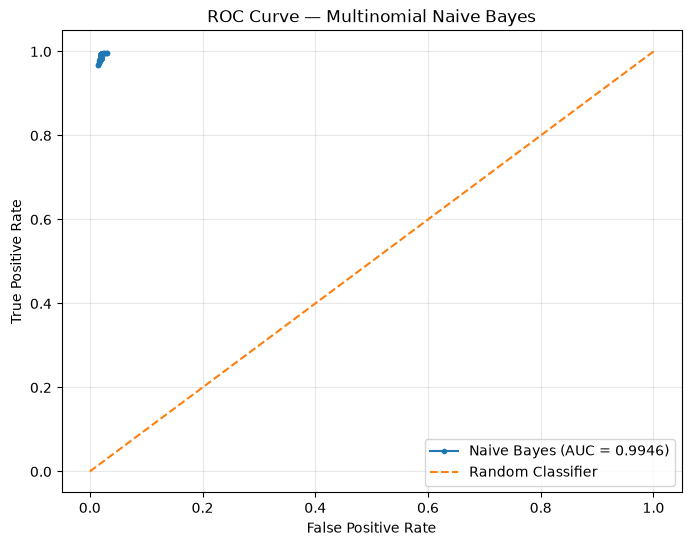

ROC CURVE COMPLETE
---------------------------------------------
Thresholds evaluated: 99
ROC AUC: 0.994632

Saved: roc.tsv


,threshold,false_positive_rate,true_positive_rate
0,0.01,0.030797,0.996503
1,0.02,0.030797,0.996503
2,0.03,0.028986,0.996503
3,0.04,0.025362,0.996503
4,0.05,0.025362,0.996503
5,0.06,0.023551,0.996503
6,0.07,0.023551,0.994755
7,0.08,0.021739,0.994755
8,0.09,0.021739,0.994755
9,0.10,0.021739,0.994755



All validation checks passed!


In [24]:
# YOUR CHANGES HERE


# ============================================================
# PART 6 — COMPUTE ROC CURVE AND SAVE roc.tsv
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. LOAD TEST PREDICTIONS
# ------------------------------------------------------------

test_predictions = pd.read_csv(
    "test-predictions.tsv",
    sep="\t"
)

# Get actual labels
test_data = test_predictions.merge(
    enron_spam_data[["Message ID", "Spam/Ham"]],
    on="Message ID",
    how="left",
    validate="one_to_one"
)

assert test_data["Spam/Ham"].notna().all()

# Spam is the positive class
y_true = (test_data["Spam/Ham"] == "spam").astype(int)
y_prob = test_data["spam"]

# ------------------------------------------------------------
# 2. CALCULATE ROC FOR 99 THRESHOLDS
# ------------------------------------------------------------

roc_results = []

for i in range(1, 100):

    threshold = i / 100

    # Predict spam if probability >= threshold
    y_pred = (y_prob >= threshold).astype(int)

    TP = ((y_true == 1) & (y_pred == 1)).sum()
    FP = ((y_true == 0) & (y_pred == 1)).sum()
    TN = ((y_true == 0) & (y_pred == 0)).sum()
    FN = ((y_true == 1) & (y_pred == 0)).sum()

    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)

    roc_results.append({
        "threshold": threshold,
        "false_positive_rate": FPR,
        "true_positive_rate": TPR
    })

# ------------------------------------------------------------
# 3. CREATE ROC DATAFRAME
# ------------------------------------------------------------

roc_df = pd.DataFrame(roc_results)

# ------------------------------------------------------------
# 4. SAVE REQUIRED FILE
# ------------------------------------------------------------

roc_df.to_csv(
    "roc.tsv",
    sep="\t",
    index=False
)

# ------------------------------------------------------------
# 5. CALCULATE AUC
# ------------------------------------------------------------

auc_score = roc_auc_score(y_true, y_prob)

# ------------------------------------------------------------
# 6. PLOT ROC CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

roc_plot = roc_df.sort_values(
    "false_positive_rate"
)

plt.plot(
    roc_plot["false_positive_rate"],
    roc_plot["true_positive_rate"],
    marker=".",
    label=f"Naive Bayes (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Multinomial Naive Bayes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ------------------------------------------------------------
# 7. VERIFY OUTPUT
# ------------------------------------------------------------

print("ROC CURVE COMPLETE")
print("-" * 45)

print("Thresholds evaluated:", len(roc_df))
print(f"ROC AUC: {auc_score:.6f}")

print("\nSaved: roc.tsv")

display(roc_df.head(10))

assert len(roc_df) == 99
assert np.isclose(roc_df["threshold"].iloc[0], 0.01)
assert np.isclose(roc_df["threshold"].iloc[-1], 0.99)

print("\nAll validation checks passed!")


Save this data in a file "roc.tsv" with columns threshold, false_positive_rate and true_positive rate.

In [25]:
# YOUR CHANGES HERE

roc_output = roc_df.rename(columns={
    "fpr": "false_positive_rate",
    "tpr": "true_positive_rate"
})

roc_output = roc_output[
    ["threshold", "false_positive_rate", "true_positive_rate"]
]


roc_output.to_csv(
    "roc.tsv",
    sep="\t",
    index=False
)


print("Saved: roc.tsv")
print("Total thresholds:", len(roc_output))

display(roc_output.head(10))


assert len(roc_output) == 99
assert np.isclose(roc_output["threshold"].iloc[0], 0.01)
assert np.isclose(roc_output["threshold"].iloc[-1], 0.99)

assert roc_output["false_positive_rate"].between(0, 1).all()
assert roc_output["true_positive_rate"].between(0, 1).all()

print("All validation checks passed!")


Saved: roc.tsv
Total thresholds: 99


,threshold,false_positive_rate,true_positive_rate
0,0.01,0.030797,0.996503
1,0.02,0.030797,0.996503
2,0.03,0.028986,0.996503
3,0.04,0.025362,0.996503
4,0.05,0.025362,0.996503
5,0.06,0.023551,0.996503
6,0.07,0.023551,0.994755
7,0.08,0.021739,0.994755
8,0.09,0.021739,0.994755
9,0.10,0.021739,0.994755


All validation checks passed!


Submit "roc.tsv" in Gradescope.

## Part 7: OpenAI API Key

Sign up for an OpenAI API acount at https://platform.openai.com/.
If you already have an OpenAI account (e.g. for ChatGPT), you may reuse that account.

Create a "dx704" project at https://platform.openai.com/settings/organization/projects, setup a $10/month spend limit, and create an API key for the project at https://platform.openai.com/api-keys.
You will use this API key for projects in later weeks.


No submission needed.

## Part 8: Code

Please submit a Jupyter notebook that can reproduce all your calculations and recreate the previously submitted files.
You do not need to provide code for data collection if you did that by manually.

## Part 9: Acknowledgements

If you discussed this assignment with anyone, please acknowledge them here.
If you did this assignment completely on your own, simply write none below.

If you used any libraries not mentioned in this module's content, please list them with a brief explanation what you used them for. If you did not use any other libraries, simply write none below.

If you used any generative AI tools, please add links to your transcripts below, and any other information that you feel is necessary to comply with the generative AI policy. If you did not use any generative AI tools, simply write none below.